## Super Mario Bros

**Super Mario Bros** (Nintendo, 1985) is a side-scrolling platform game for the NES console: Mario has to reach the flag at the end of the level by running to the right, jumping over pipes and gaps and avoiding (or stomping) the enemies, before the clock runs out. The [gym-super-mario-bros](https://pypi.org/project/gym-super-mario-bros/) package provides the game as a Gymnasium environment, built on the [nes-py](https://pypi.org/project/nes-py/) emulator of the NES; the ROM of the game is included in the package, so there is nothing else to install.

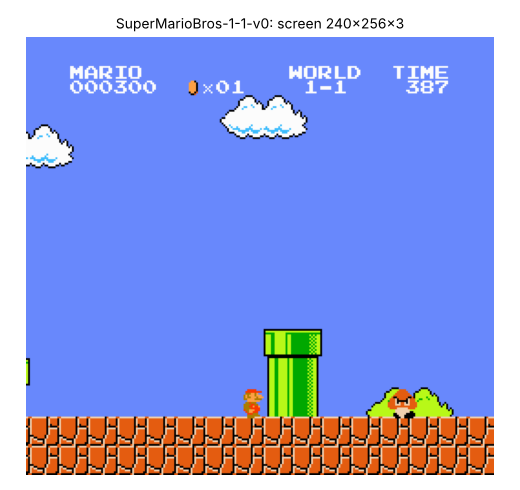

The objective of this notebook is to **train an agent to complete the first level of the game with the PPO algorithm of the notes, learning from raw pixel data**. We reuse the structure of the notes (parallel environments, rollouts, GAE, clipped objective) and we change what the new environment requires:

- the **state is an image**, so the networks become convolutional, as in the Pong lab of Chapter 07, and the rollouts must be stored compactly;
- the **environment is slow** (an emulated console instead of a few equations of motion), so a training takes hours and the code needs checkpoints;
- the **reward is a signal designed by the authors of the package**, not the score of the game, so we must understand what the agent is actually asked to maximise, and we need a better progress measure than the return.

The notebook is organised in four parts: the environment (tasks 1-8), the agent (tasks 9-14), the training (tasks 15-17) and the generalisation test (tasks 18-19). Super Mario Bros is also a classic benchmark of exploration, used for instance in [D. Pathak et al., **"Curiosity-driven Exploration by Self-supervised Prediction"**, ICML 2017](https://arxiv.org/abs/1705.05363): whole sections of a level are reached only through long chains of actions that no random policy produces.

**Installation**: `pip install gym-super-mario-bros opencv-python`. Version 9 or later of the package is required (it is the first one built on Gymnasium rather than on the old `gym` API). When no prebuilt wheel is available for your platform, `pip` compiles the C++ emulator of nes-py and needs a C++ compiler (on macOS, the Xcode command line tools).

### Part I - The environment

1 - Import Gymnasium and gym-super-mario-bros (importing the package registers the environments with Gymnasium), create an instance of the first level of the game, `SuperMarioBros-1-1-v0`, with render_mode="rgb_array", and print the sizes of the state and action spaces. The observation is the NES screen: 240x256 RGB pixels. The action space is Discrete(256): an action is a byte whose 8 bits are the 8 buttons of the NES controller (right, left, down, up, start, select, B, A), so that any combination of buttons can be pressed at the same time.

In [31]:
import gymnasium
import gym_super_mario_bros   # registers the Super Mario Bros environments with Gymnasium

mario = gymnasium.make("SuperMarioBros-1-1-v0", render_mode="rgb_array")

print("State Space: ", mario.observation_space.shape)
print("Action Space: ", mario.action_space.n)

State Space:  (240, 256, 3)
Action Space:  256


2 - 256 combinations of buttons are far too many, and most of them are useless (left and right together, start in the middle of a level). The package provides three lists of meaningful combinations:

- RIGHT_ONLY, 5 actions: no-op, right, right+A, right+B, right+A+B;
- SIMPLE_MOVEMENT, 7 actions: the previous ones, plus A alone and left;
- COMPLEX_MOVEMENT, 12 actions: adds the combinations with left, down and up.

A is jump and B is run. The longer A is held, the higher the jump: the agent will have to learn to repeat the same action for several consecutive steps. Apply the JoypadSpace wrapper of nes-py with SIMPLE_MOVEMENT, which maps each discrete action to its byte, and print the meaning of each action.

In [2]:
from nes_py.wrappers import JoypadSpace
from gym_super_mario_bros.actions import RIGHT_ONLY, SIMPLE_MOVEMENT, COMPLEX_MOVEMENT

mario = JoypadSpace(mario, SIMPLE_MOVEMENT)

print("Action Space: ", mario.action_space.n)
for action, meaning in enumerate(mario.get_action_meanings()):
    print(f"  {action}: {meaning}")

Action Space:  7
  0: NOOP
  1: right
  2: right A
  3: right B
  4: right A B
  5: A
  6: left


3 - Define a random policy and the show_policy() function of the notes (a policy is a function that maps a state to an action), and watch a few hundred steps of the game. The info dictionary returned by step() contains the state of the game, read from the RAM of the emulator: Mario's horizontal position x_pos (in pixels from the start of the level) and the best one reached so far x_pos_max, the clock time, coins, score, the status (small, tall, fireball), life, and flag_get, which becomes true when Mario reaches the flag at the end of the level. The agent will never see these values (it sees only pixels), but they are precious for us: the flag of the first level is at 3161 pixels, so x_pos_max tells at a glance how far the agent got.

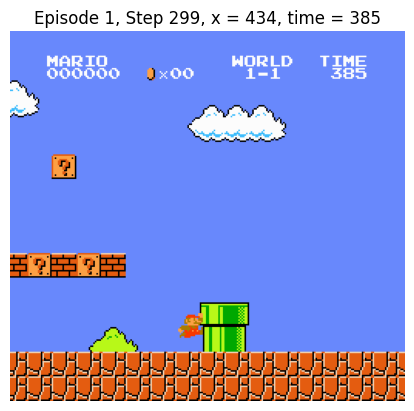

In [3]:
import numpy as np
import random
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output

def random_pi(state):
    # the state is unused, but keeps the same interface as the other policies
    return mario.action_space.sample()


def show_policy(env, policy, n_episodes=1, max_steps=500):

    for episode in range(n_episodes):

        # reset the environment
        state, _ = env.reset()
        done = False
        step = 0

        # run the episode until done or max_steps
        while not done and step < max_steps:

            # make a step
            action = policy(state)
            state, _, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # render the environment
            clear_output(wait=True)
            plt.imshow(env.render())
            plt.axis("off")
            plt.title(f"Episode {episode + 1}, Step {step}, x = {info['x_pos']}, time = {info['time']}")
            plt.show()
            plt.close()

            step += 1


show_policy(mario, random_pi, n_episodes=1, max_steps=300)

4 - The evaluate() function of the notes returns the average return. Here the return is hard to interpret (the reward is a shaped signal, see task 5), while "how far did Mario get" is not. Write a run_episode() function that runs one episode and returns a dictionary with the return, the progress (x_pos_max), whether the flag was reached and the number of steps; evaluate() averages these quantities over the episodes. Evaluate the random policy over a few episodes.

In [4]:
def run_episode(env, policy, max_steps=10_000):

    state, info = env.reset()
    total_reward, steps, done = 0.0, 0, False

    # run one episode
    while not done and steps < max_steps:
        state, reward, terminated, truncated, info = env.step(policy(state))
        total_reward += reward
        steps += 1
        done = terminated or truncated

    # the return, plus the game statistics read from the RAM
    return {
        "return": total_reward,
        "progress": info["x_pos_max"],
        "flag": float(info["flag_get"]),
        "steps": steps,
    }


def evaluate(env, policy, episodes=1):

    results = [run_episode(env, policy) for _ in range(episodes)]

    # average each quantity over the episodes
    return {key: float(np.mean([result[key] for result in results])) for key in results[0]}


random_results = evaluate(mario, random_pi, episodes=3)
print("Random policy:", random_results)

Random policy: {'return': 142.33333333333334, 'progress': 595.0, 'flag': 0.0, 'steps': 8019.0}


Four of the seven actions of SIMPLE_MOVEMENT move to the right, so the random agent drifts rightwards and typically dies against the first Goomba, at about 600 pixels, or gets stuck at the first pipes. In the latter case the episode lasts until the 400 units of the in-game clock run out: about 9600 frames.

5 - The reward of the environment is **not the score of the game**. It is a **shaped signal**, computed from the RAM at every frame as a sum of components:

| component | value |
|---|---|
| progress | increase of the best horizontal position reached so far (at most 5 pixels per frame; moving back gives nothing) |
| time | -1 every time the in-game clock ticks |
| score | increase of the game score, divided by 100 |
| coins | +5 per coin |
| powerup | +5 when Mario grows, -5 when it shrinks |
| completion | +50 when the flag is reached |
| death | -25 when Mario dies |

The total is **clipped to [-15, 15]**, so the completion bonus and the death penalty are actually $\pm 15$. In other words, the agent is asked to run to the right as fast as possible, and dying costs about three steps of running. Run one episode with the random policy, printing from time to time the reward and its components (info["reward_components"]), and check the clipping at the end: in a single-level environment the episode terminates at the first death or at the flag (so there is no need of the "one episode per life" trick of the Atari games).

In [5]:
state, info = mario.reset()
done, step = False, 0

while not done:
    state, reward, terminated, truncated, info = mario.step(random_pi(state))
    done = terminated or truncated

    # print one step out of 20 with a non-zero reward, and the last one
    components = {key: value for key, value in info["reward_components"].items() if value != 0}
    if (reward != 0 and step % 20 == 0) or done:
        print(f"frame {step:5d}, x = {info['x_pos']:4d}, time = {info['time']}, reward = {reward:+6.1f}, "
              f"unclipped = {info['reward_total_unclipped']:+6.1f}, components = {components}")
    step += 1

print("Terminated:", terminated, "- dead:", info["is_dead"] or info["is_dying"], "- flag:", info["flag_get"])

frame    20, x =   47, time = 399, reward =   +1.0, unclipped =   +1.0, components = {'progress': 1.0}
frame    40, x =   61, time = 398, reward =   +1.0, unclipped =   +1.0, components = {'progress': 1.0}
frame    60, x =   81, time = 397, reward =   +2.0, unclipped =   +2.0, components = {'progress': 2.0}
frame    80, x =  117, time = 396, reward =   +3.0, unclipped =   +3.0, components = {'progress': 3.0}
frame   100, x =  166, time = 395, reward =   +2.0, unclipped =   +2.0, components = {'progress': 2.0}
frame   120, x =  217, time = 394, reward =   +3.0, unclipped =   +3.0, components = {'progress': 3.0}
frame   140, x =  276, time = 393, reward =   +2.0, unclipped =   +2.0, components = {'progress': 2.0}
frame   160, x =  335, time = 392, reward =   +3.0, unclipped =   +3.0, components = {'progress': 3.0}
frame   180, x =  393, time = 391, reward =   +3.0, unclipped =   +3.0, components = {'progress': 3.0}
frame   200, x =  430, time = 390, reward =   +2.0, unclipped =   +2.0, c

6 - The scale of the reward matters. PPO normalises the advantages inside each mini-batch, so the policy loss does not depend on it, but the critic regresses on the actual returns: with rewards of the order of 10 per frame, the value loss would dominate the combined loss of the shared network (task 9) at the beginning of training. Apply the TransformReward wrapper to divide the reward by 15, so that the reward of a frame is in [-1, 1].

In [6]:
mario = gymnasium.wrappers.TransformReward(mario, lambda reward: reward / 15.0)

7 - The emulator runs at 60 frames per second and consecutive frames are nearly identical. As in the Pong lab, we let the agent choose an action every 4 frames, repeating it in between and summing the rewards of the skipped frames: four times fewer decisions for the same game. The AtariPreprocessing wrapper did this for the Atari games; write a SkipFrame wrapper for the NES, a class that extends gymnasium.Wrapper and overrides step(). (The NES screen does not flicker like that of the Atari 2600, so there is no need of the maximum over the last two frames.)

In [7]:
class SkipFrame(gymnasium.Wrapper):

    def __init__(self, env, skip=4):
        super().__init__(env)
        self.skip = skip

    def step(self, action):

        total_reward = 0.0

        # repeat the action for skip frames, summing the rewards
        for _ in range(self.skip):
            state, reward, terminated, truncated, info = self.env.step(action)
            total_reward += reward
            if terminated or truncated:
                break

        return state, total_reward, terminated, truncated, info


mario = SkipFrame(mario, skip=4)

8 - Feeding the raw 240x256x3 screen to the network would be wasteful: the colours are not needed and the image can be shrunk. Write a PreprocessFrame wrapper, a class that extends gymnasium.ObservationWrapper and overrides observation(), that converts the frame to grayscale and resizes it to 84x84 pixels, keeping the uint8 format (one byte per pixel: four times less memory than float32 when we store the rollouts), and declares the new observation space. Gymnasium provides GrayscaleObservation and ResizeObservation for this, but a single wrapper based on OpenCV is several times faster, and speed matters: a step of the emulator takes a few milliseconds, and we will take millions of them.

Then, as in Pong, stack the last 4 frames with the FrameStackObservation wrapper: a single frame does not tell how things are moving (is Mario going up or falling? is the Goomba walking towards him?), four do.

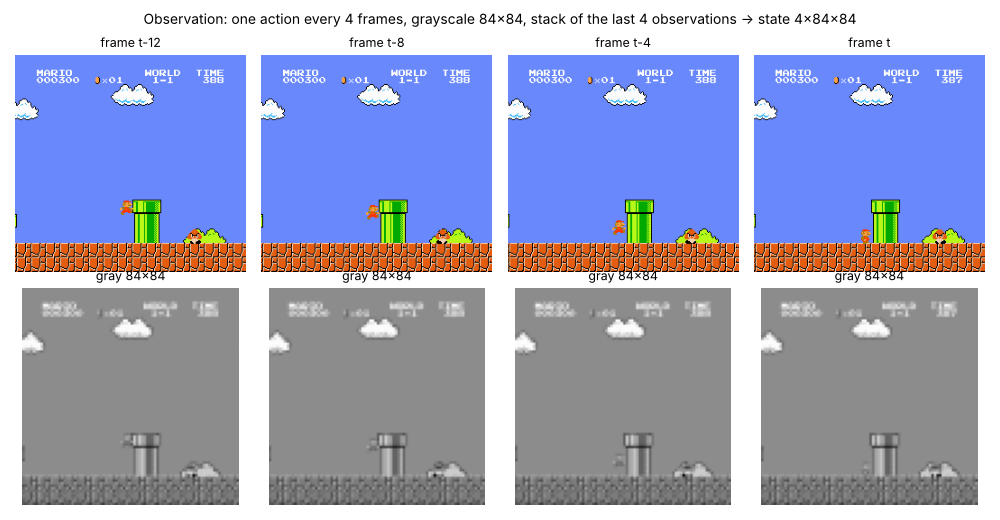

In [8]:
import cv2

class PreprocessFrame(gymnasium.ObservationWrapper):

    def __init__(self, env, size=84):
        super().__init__(env)
        self.size = size
        # the new observation: a size x size grayscale image, uint8 pixels
        self.observation_space = gymnasium.spaces.Box(low=0, high=255, shape=(size, size), dtype=np.uint8)

    def observation(self, frame):
        gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
        return cv2.resize(gray, (self.size, self.size), interpolation=cv2.INTER_AREA)


mario = PreprocessFrame(mario, size=84)
print("State Space after preprocessing: ", mario.observation_space.shape)

mario = gymnasium.wrappers.FrameStackObservation(mario, 4)
print("State Space after stacking:      ", mario.observation_space.shape)   # (4, 84, 84)

State Space after preprocessing:  (84, 84)
State Space after stacking:       (4, 84, 84)


Let us collect the wrappers in two functions, to be used from now on: wrap_mario_env() applies them, in the right order, to a raw environment (the reward scaling and the frame skipping act on the raw rewards, the preprocessing and the stacking on the raw frames); make_mario_env() creates the environment of a level and wraps it. Keeping the two separate will allow us to wrap a different base environment in task 18. The last wrapper, RecordEpisodeStatistics of Gymnasium, adds to the info dictionary, at the end of every episode, its return (info["episode"]["r"]) and its length (info["episode"]["l"]): we will use it to monitor the training episodes. The seed_environment() function is that of the Pong lab.

In [9]:
import torch

def wrap_mario_env(env, actions=SIMPLE_MOVEMENT, reward_scale=15.0):

    # discrete actions: a list of button combinations
    env = JoypadSpace(env, actions)

    # rewards scaled to [-1, 1] per frame, one action every 4 frames
    env = gymnasium.wrappers.TransformReward(env, lambda reward: reward / reward_scale)
    env = SkipFrame(env, skip=4)

    # 84x84 grayscale frames, stacked 4 by 4
    env = PreprocessFrame(env, size=84)
    env = gymnasium.wrappers.FrameStackObservation(env, 4)

    # return and length of every episode in info["episode"]
    env = gymnasium.wrappers.RecordEpisodeStatistics(env)

    return env


def make_mario_env(stage="1-1", actions=SIMPLE_MOVEMENT, reward_scale=15.0, render_mode="rgb_array"):

    # the game, restricted to one level
    env = gymnasium.make(f"SuperMarioBros-{stage}-v0", render_mode=render_mode)

    return wrap_mario_env(env, actions, reward_scale)


def seed_environment(env, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    env.reset(seed=seed)
    env.action_space.seed(seed)


mario = make_mario_env("1-1")
seed_environment(mario, seed=42)

print("State Space: ", mario.observation_space.shape)
print("Action Space: ", mario.action_space.n)

State Space:  (4, 84, 84)
Action Space:  7


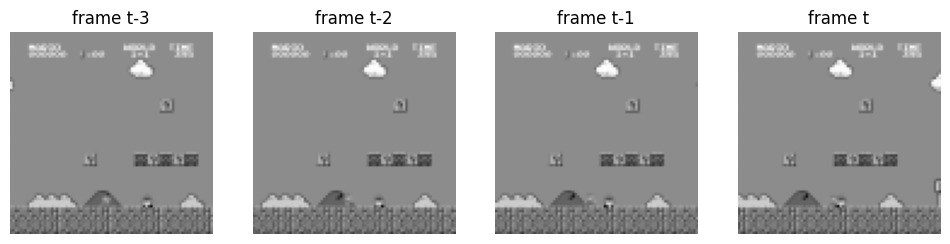

In [10]:
# run a few steps to the right, then show the four frames of the state
state, _ = mario.reset()
for _ in range(40):
    state, _, terminated, truncated, _ = mario.step(4)    # right + A + B
    if terminated or truncated:
        break

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for k in range(4):
    axes[k].imshow(state[k], cmap="gray", vmin=0, vmax=255)
    axes[k].set_title(f"frame t-{3 - k}" if k < 3 else "frame t")
    axes[k].axis("off")
plt.show()

Note that **the emulator is deterministic**: the same sequence of actions always produces the same frames. The seed does not change the game; it only affects the initialisation of the networks and the sampling of the actions. We will come back to this in task 18.

### Part II - The agent

9 - Since the states are images, the policy and the value networks must be convolutional. In the notes they are two separate networks; here we use a **single network with a shared trunk**: the convolutional feature extractor of the Pong lab (three convolutional layers and a fully connected layer with 512 units), followed by two linear heads, one returning the preferences (logits) of the actions and the other the value of the state.

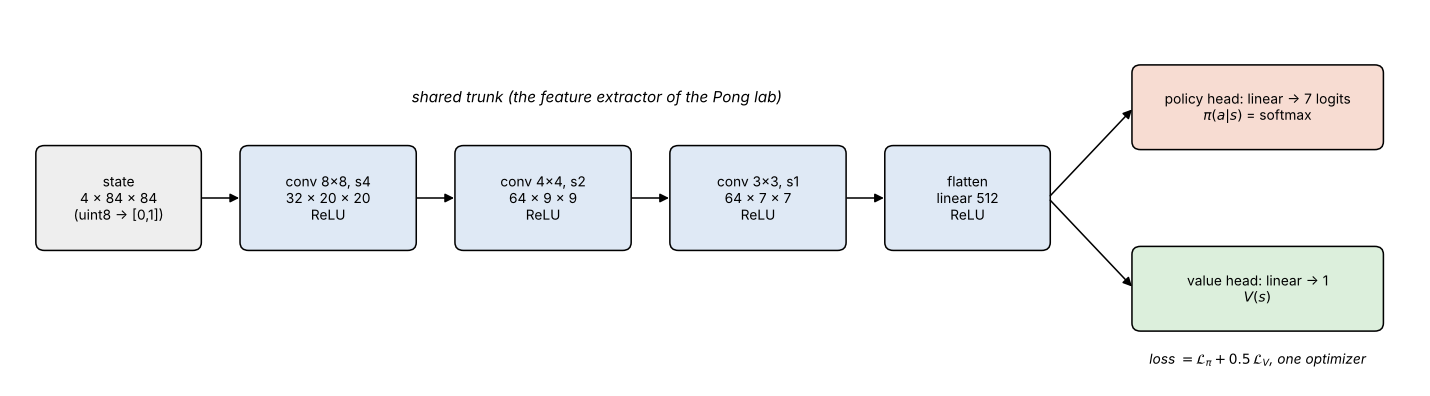

Why share? The features needed to choose the action (where are the gaps, the enemies, the pipes) are the same needed to estimate the value; the trunk is by far the most expensive part of the network, and sharing it halves the computation and trains it with two signals instead of one. This is the standard choice for PPO on images. The price is that the two heads can no longer have separate optimizers: the policy and the value losses will be combined into a single loss (task 13). Implement the ActorCriticNetwork class, whose forward() returns the logits and the values, create it on the GPU when one is available, and write the to_tensor() helper that converts a batch of uint8 states into a float tensor in [0, 1] on the right device.

In [11]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps"  if torch.backends.mps.is_available() else "cpu"
)
print("Device:", device)

Device: mps


In [12]:
class ActorCriticNetwork(torch.nn.Module):

    def __init__(self, env, hidden=512):
        super().__init__()

        # number of stacked frames and number of actions
        frames = env.observation_space.shape[0]
        actions = env.action_space.n

        # shared trunk: the convolutional network of the Pong lab
        self.features = torch.nn.Sequential(
            # input: frames x 84 x 84 (pixels scaled to [0, 1])
            torch.nn.Conv2d(frames, 32, kernel_size=8, stride=4),   # -> 32 x 20 x 20
            torch.nn.ReLU(),
            torch.nn.Conv2d(32, 64, kernel_size=4, stride=2),       # -> 64 x 9 x 9
            torch.nn.ReLU(),
            torch.nn.Conv2d(64, 64, kernel_size=3, stride=1),       # -> 64 x 7 x 7
            torch.nn.ReLU(),
            torch.nn.Flatten(),
            torch.nn.Linear(7 * 7 * 64, hidden),
            torch.nn.ReLU(),
        )

        # two heads: the action preferences (logits) and the state value
        self.policy_head = torch.nn.Linear(hidden, actions)
        self.value_head = torch.nn.Linear(hidden, 1)

    def forward(self, states):
        features = self.features(states)
        return self.policy_head(features), self.value_head(features).squeeze(-1)


def to_tensor(states):
    # uint8 frames -> float tensor in [0, 1] on the device of the network (a float tensor is returned as it is)
    if torch.is_tensor(states) and states.dtype == torch.float32:
        return states
    return torch.as_tensor(np.asarray(states), dtype=torch.float32, device=device) / 255.0


net = ActorCriticNetwork(mario).to(device)
print(net)

ActorCriticNetwork(
  (features): Sequential(
    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=3136, out_features=512, bias=True)
    (8): ReLU()
  )
  (policy_head): Linear(in_features=512, out_features=7, bias=True)
  (value_head): Linear(in_features=512, out_features=1, bias=True)
)


10 - Write the policy_distribution() function of the notes: it takes a batch of states and returns the categorical distribution of the actions and, since the network has two heads, also the values, from a single forward pass. Then write the stochastic_pi() and greedy_pi() policies of the notes: they receive a single state, which must be given a batch dimension.

In [13]:
def policy_distribution(states):

    # one forward pass: the preferences define the action distribution, the second head the values
    logits, values = net(to_tensor(states))

    return torch.distributions.Categorical(logits=logits), values


def stochastic_pi(state):

    # sample an action from the policy, as during training
    with torch.no_grad():
        dist, _ = policy_distribution(np.asarray(state)[None])

    return int(dist.sample().item())


def greedy_pi(state):

    # select the most probable action
    with torch.no_grad():
        dist, _ = policy_distribution(np.asarray(state)[None])

    return int(dist.logits.argmax(dim=-1).item())


# an untrained network: the greedy policy repeats the same action, the stochastic one is nearly uniform
print("Untrained greedy policy:    ", evaluate(mario, greedy_pi, episodes=1))
print("Untrained stochastic policy:", evaluate(mario, stochastic_pi, episodes=1))

Untrained greedy policy:     {'return': -27.666666666666593, 'progress': 40.0, 'flag': 0.0, 'steps': 2005.0}
Untrained stochastic policy: {'return': 15.73333333333333, 'progress': 300.0, 'flag': 0.0, 'steps': 42.0}


11 - Write the create_environments() function of the notes: it creates the $K$ parallel environments with make_mario_env(), seeds them and returns them together with their initial states, as a uint8 array. The keyword arguments are passed on to make_mario_env(), so that the same function can create environments of other levels.

In [14]:
def create_environments(n_envs, seed, **env_kwargs):

    # K independent copies of the environment, each with its own seed
    envs = [make_mario_env(**env_kwargs) for _ in range(n_envs)]

    states = []
    for i, env in enumerate(envs):
        state, _ = env.reset(seed=seed + i)
        env.action_space.seed(seed + i)
        states.append(state)

    return envs, np.array(states, dtype=np.uint8)

12 - Write the collect_rollout() function of the notes. The structure is the same: $n$ steps in the $K$ environments with the current policy, one batched forward pass per step, bootstrap on truncation, reset at the end of an episode, the values of the last states for the unfinished episodes. Two things change:

- the states are images: the rollout stores them in a **preallocated uint8 array** of shape (n, K, 4, 84, 84), 29 MB with $n = 128$ and $K = 8$ (as float32 it would be four times as much), and the actions, log-probabilities and values come from the single forward pass of policy_distribution();
- the function receives a list, episodes, to which it appends the statistics of every **training episode** that ends (return and length from info["episode"], progress and flag from the game): evaluating the policy on Mario is slow (an episode of a stuck policy lasts about 2000 steps, until the clock runs out), while the training episodes are free.

In [15]:
def collect_rollout(envs, states, n_steps, gamma, episodes):

    n_envs = len(envs)

    # quantities recorded along the rollout, one row per step, one column per environment
    rollout_states = np.zeros((n_steps, n_envs) + states.shape[1:], dtype=np.uint8)
    rollout_actions = torch.zeros((n_steps, n_envs), dtype=torch.long)
    logpas = torch.zeros((n_steps, n_envs))
    values = np.zeros((n_steps, n_envs), dtype=np.float32)
    rewards = np.zeros((n_steps, n_envs), dtype=np.float32)
    dones = np.zeros((n_steps, n_envs), dtype=np.float32)

    for t in range(n_steps):

        # one batched forward pass for all the environments, without gradient
        with torch.no_grad():
            dist, state_values = policy_distribution(states)
            actions = dist.sample()

            rollout_states[t] = states
            rollout_actions[t] = actions.cpu()
            logpas[t] = dist.log_prob(actions).cpu()
            values[t] = state_values.cpu().numpy()

        # step every environment with its own action
        next_states = np.zeros_like(states)

        for i, env in enumerate(envs):
            next_state, reward, terminated, truncated, info = env.step(int(actions[i]))

            # a truncated episode has a future: bootstrap on the state reached
            if truncated and not terminated:
                with torch.no_grad():
                    _, last_value = policy_distribution(np.asarray(next_state)[None])
                reward += gamma * last_value.item()

            # at the end of an episode, record its statistics and start a new one
            if terminated or truncated:
                episodes.append({
                    "return": float(info["episode"]["r"]),
                    "steps": int(info["episode"]["l"]),
                    "progress": info["x_pos_max"],
                    "flag": float(info["flag_get"]),
                })
                next_state, _ = env.reset()

            rewards[t, i] = reward
            dones[t, i] = float(terminated or truncated)
            next_states[i] = next_state

        states = next_states

    # the critic's estimate of the last states, to bootstrap the unfinished episodes
    with torch.no_grad():
        _, last_values = policy_distribution(states)
        last_values = last_values.cpu().numpy()

    rollout = {
        "states": rollout_states,
        "actions": rollout_actions,
        "logpas": logpas,
        "values": values,
        "rewards": rewards,
        "dones": dones,
        "last_values": last_values,
    }

    return rollout, states

13 - The GAE advantages and the critic targets do not depend on the nature of the states: copy the compute_gae() function of the notes.

In [16]:
def compute_gae(rewards, dones, values, last_values, gamma=0.99, lam=0.95):

    advantages = np.zeros_like(rewards)
    future_advantage = np.zeros_like(last_values)
    next_values = last_values

    for t in reversed(range(len(rewards))):

        # one-step TD error, with no future value after a terminal state
        td_error = rewards[t] + gamma * (1.0 - dones[t]) * next_values - values[t]

        # A_t = delta_t + gamma * lambda * (1 - d_{t+1}) * A_{t+1}
        future_advantage = td_error + gamma * lam * (1.0 - dones[t]) * future_advantage
        advantages[t] = future_advantage

        next_values = values[t]

    # the critic target is the advantage plus the current value (the lambda-return)
    returns = advantages + values

    return torch.as_tensor(advantages), torch.as_tensor(returns)

14 - Write the optimize() function of the notes. The clipped surrogate, the entropy bonus and the value regression are unchanged; what changes is how they are minimised, because the network is shared. The policy loss and the value loss are combined into a single loss,

$\mathcal{L} = \mathcal{L}_\pi + c_v \, \mathcal{L}_V, \qquad c_v = 0.5,$

minimised by a single optimizer with gradient-norm clipping (the coefficient $c_v$ balances the two signals that reach the trunk: it is the reason why the scale of the reward mattered in task 6). One more practical detail: the rollout stays on the CPU as uint8, and only the mini-batch of states is converted to float and moved to the device (the whole rollout as float32 on the GPU would take 115 MB); the approximate KL divergence used as diagnostic is computed in mini-batches for the same reason. (The optional augment argument, a function applied to the mini-batch of states, will be used in task 20: ignore it for now.)

In [17]:
def optimize(rollout, advantages, returns, epochs=4, minibatch_size=256, epsilon=0.2, beta=0.01,
             value_coefficient=0.5, max_gradient_norm=0.5, augment=None):

    # flatten the rollout into a batch of K x n transitions (the states stay on the CPU as uint8)
    n_steps, n_envs = rollout["rewards"].shape
    batch_size = n_steps * n_envs

    states = rollout["states"].reshape(batch_size, *rollout["states"].shape[2:])
    actions = rollout["actions"].reshape(batch_size).to(device)
    old_logpas = rollout["logpas"].reshape(batch_size).to(device)
    advantages = advantages.reshape(batch_size).to(device)
    returns = returns.reshape(batch_size).to(device)

    for epoch in range(epochs):

        # shuffle the transitions and split them into mini-batches
        permutation = torch.randperm(batch_size)

        for start in range(0, batch_size, minibatch_size):

            indices = permutation[start:start + minibatch_size]

            # the mini-batch of states, optionally augmented (task 20)
            minibatch_states = states[indices.numpy()]
            if augment is not None:
                minibatch_states = augment(to_tensor(minibatch_states))

            # re-evaluate the current policy (and the values) on the stored states and actions
            dist, values = policy_distribution(minibatch_states)
            new_logpas = dist.log_prob(actions[indices])
            entropy = dist.entropy()

            # probability ratios between the current and the old policy
            ratios = (new_logpas - old_logpas[indices]).exp()

            # advantages normalised within the mini-batch
            minibatch_advantages = advantages[indices]
            minibatch_advantages = (minibatch_advantages - minibatch_advantages.mean()) / (minibatch_advantages.std() + 1e-8)

            # clipped surrogate objective: the minimum of the unclipped and clipped terms
            unclipped = ratios * minibatch_advantages
            clipped = ratios.clamp(1.0 - epsilon, 1.0 + epsilon) * minibatch_advantages
            surrogate = torch.min(unclipped, clipped).mean()

            # policy loss: minus the surrogate, minus the entropy bonus
            policy_loss = -(surrogate + beta * entropy.mean())

            # value loss: regression of V(s) towards the GAE returns
            value_loss = (returns[indices] - values).pow(2).mean()

            # a single loss for the shared network
            loss = policy_loss + value_coefficient * value_loss

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), max_gradient_norm)
            optimizer.step()

    # approximate KL divergence between the old and the new policy over the whole rollout (diagnostic)
    with torch.no_grad():
        kls = []
        for start in range(0, batch_size, minibatch_size):
            minibatch = slice(start, start + minibatch_size)
            dist, _ = policy_distribution(states[minibatch])
            ratios = (dist.log_prob(actions[minibatch]) - old_logpas[minibatch]).exp()
            kls.append(((ratios - 1.0) - ratios.log()).mean().item())

    return float(np.mean(kls))

### Part III - Training

15 - Write the ppo() training loop of the notes. The core is identical: collect a rollout, compute the advantages, optimize, repeat until the budget of environment steps is spent. A training that takes hours needs the same three additions of the Pong lab:

- **evaluation** of the greedy policy every eval_every environment steps, on a single episode: the emulator and the greedy policy are both deterministic, so one episode gives the exact score; the statistics of the training episodes, collected during the rollouts, complete the picture;
- a **checkpoint** at every evaluation (network, optimizer, history and random generators), saved in the temp folder, so that an interrupted run resumes where it stopped: the training cell can be interrupted and run again;
- the **best policy** found so far, saved separately in the temp folder, where "best" means the longest progress along the level (the final weights are not necessarily the best ones).

The function creates the network and its optimizer (Adam, with a single learning rate), the $K$ environments and a separate evaluation environment, and returns a history with two lists of records: the evaluations (step, return, progress, flag, approximate KL) and the training episodes. Write the saving and loading of the checkpoint as two helper functions, to keep the loop readable.

In [18]:
import os

def save_checkpoint(path, history):
    torch.save({
        "network": net.state_dict(),
        "optimizer": optimizer.state_dict(),
        "history": history,
        "torch_rng": torch.get_rng_state(),
        "numpy_rng": np.random.get_state(),
        "python_rng": random.getstate(),
    }, path)


def load_checkpoint(path):
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    net.load_state_dict(checkpoint["network"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    torch.set_rng_state(checkpoint["torch_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    random.setstate(checkpoint["python_rng"])
    return checkpoint["history"]

In [19]:
def ppo(max_steps, eval_every=50_000, n_envs=8, n_steps=128, epochs=4, minibatch_size=256,
        gamma=0.9, lam=0.95, epsilon=0.2, beta=0.01, learning_rate=0.00025,
        checkpoint_name="mario_ppo", seed=42, env_kwargs={}, augment=None, verbose=True):

    global net, optimizer

    os.makedirs("temp", exist_ok=True)
    checkpoint_file = os.path.join("temp", f"{checkpoint_name}_checkpoint.pt")
    best_file = os.path.join("temp", f"{checkpoint_name}_best.pt")

    # seeds, the K environments and a separate evaluation environment
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    envs, states = create_environments(n_envs, seed, **env_kwargs)
    eval_env = make_mario_env(**env_kwargs)
    eval_env.reset(seed=seed + n_envs)

    # the shared network and its optimizer
    net = ActorCriticNetwork(eval_env).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate, eps=1e-5)

    # the history: evaluations and training episodes, plus the counters needed to resume
    history = {"evaluations": [], "episodes": [], "best_progress": -1.0, "total_steps": 0, "elapsed": 0.0}

    # resume from the checkpoint, if there is one
    if os.path.exists(checkpoint_file):
        history = load_checkpoint(checkpoint_file)
        if verbose:
            print(f"Resumed from {checkpoint_file} at step {history['total_steps']}")

    total_steps = history["total_steps"]
    next_evaluation = (total_steps // eval_every + 1) * eval_every
    start_time = time.time() - history["elapsed"]

    while total_steps < max_steps:

        # collect a rollout of n steps in the K environments with the current policy
        rollout, states = collect_rollout(envs, states, n_steps, gamma, history["episodes"])
        total_steps += n_steps * n_envs

        # GAE advantages and critic targets
        advantages, returns = compute_gae(rollout["rewards"], rollout["dones"], rollout["values"], rollout["last_values"], gamma, lam)

        # several epochs of mini-batch updates on the same rollout
        approximate_kl = optimize(rollout, advantages, returns, epochs, minibatch_size, epsilon, beta, augment=augment)

        if total_steps >= next_evaluation:
            next_evaluation += eval_every

            # evaluate the greedy policy (deterministic: one episode is enough)
            evaluation = evaluate(eval_env, greedy_pi, episodes=1)
            evaluation.update(step=total_steps, kl=approximate_kl)
            history["evaluations"].append(evaluation)
            history["total_steps"] = total_steps
            history["elapsed"] = time.time() - start_time

            # save the best policy found so far (the one that gets farthest)
            if evaluation["progress"] > history["best_progress"]:
                history["best_progress"] = evaluation["progress"]
                torch.save({"network": net.state_dict(), "evaluation": evaluation}, best_file)

            # save the checkpoint
            save_checkpoint(checkpoint_file, history)

            if verbose:
                recent = history["episodes"][-20:]
                print(f"Step {total_steps:>8} | greedy: x {evaluation['progress']:5.0f}, return {evaluation['return']:6.1f}, flag {int(evaluation['flag'])}"
                      f" | last {len(recent)} training episodes: x {np.mean([e['progress'] for e in recent]):5.0f},"
                      f" return {np.mean([e['return'] for e in recent]):6.1f}, flags {int(sum(e['flag'] for e in recent))}"
                      f" | KL {approximate_kl:.4f} | {history['elapsed'] / 60:.0f} min")

    for env in envs:
        env.close()
    eval_env.close()

    return history

16 - Train the agent. As in the Pong lab, a train() function runs the algorithm, saves the history in the temp folder with joblib and reloads it when the cell is run again; on this environment a single seed is already expensive, so we use one. The hyperparameters are those of the notes, with two differences:

- a single learning rate ($2.5 \cdot 10^{-4}$), since the network is shared;
- a **discount factor $\gamma = 0.9$**, lower than the usual $0.99$. The reward is dense (a few pixels of progress at every step) and what happens far in the future depends little on the current action, so a short horizon (about $1/(1-\gamma) = 10$ steps) gives the critic much less noisy targets. $\gamma = 0.99$ works too, but learns more slowly (try it, task 19).

The budget is 2 million environment steps, i.e. 8 million frames. The emulator is the bottleneck (the 8 environments are stepped one after the other, in the same process): the run below took about 2 hours on a laptop with Apple silicon (270 steps per second), and takes 4-6 hours on a CPU-only machine. Do not expect quick results: the random policy already gets to about 600 pixels, and the first pipes and the first gap (between 600 and 1300 pixels) are passed only when the agent learns to hold the jump button for several consecutive steps. In our run the training episodes stayed below 1000 pixels for the first 450.000 steps, the first flags appeared at about 800.000 steps, and from 1.35 million steps on the greedy policy completed the level at almost every evaluation. The training can be stopped and resumed at any time, and the plots of task 17 can be drawn from the checkpoint.

In [20]:
from pathlib import Path
import joblib

def train(name, **parameters):

    # load the results of a previously saved training
    results_path = Path("temp") / f"{name}_results.joblib"
    if results_path.exists():
        print(f"Loaded results from {results_path}")
        return joblib.load(results_path)

    # train (resuming from the checkpoint, if any) and save the history
    history = ppo(checkpoint_name=name, **parameters)
    joblib.dump(history, results_path)

    return history


mario_ppo = train(
    name="mario_ppo",
    max_steps=2_000_000,
    eval_every=50_000,

    # rollout and optimization, as in the notes
    n_envs=8,
    n_steps=128,
    epochs=4,
    minibatch_size=256,
    epsilon=0.2,
    beta=0.01,
    lam=0.95,

    # the short horizon and the single learning rate of the shared network
    gamma=0.9,
    learning_rate=0.00025,

    seed=42,
)

Step    50176 | greedy: x   434, return   -1.3, flag 0 | last 20 training episodes: x   955, return   58.5, flags 0 | KL 0.0117 | 3 min
Step   100352 | greedy: x   314, return   16.7, flag 0 | last 20 training episodes: x   778, return   47.0, flags 0 | KL 0.0106 | 7 min
Step   150528 | greedy: x   314, return   16.7, flag 0 | last 20 training episodes: x   686, return   41.0, flags 0 | KL 0.0063 | 10 min
Step   200704 | greedy: x   314, return   16.7, flag 0 | last 20 training episodes: x   928, return   56.8, flags 0 | KL 0.0074 | 13 min
Step   250880 | greedy: x   314, return   16.7, flag 0 | last 20 training episodes: x   884, return   54.0, flags 0 | KL 0.0019 | 16 min
Step   300032 | greedy: x   314, return   16.7, flag 0 | last 20 training episodes: x   915, return   55.9, flags 0 | KL 0.0014 | 19 min
Step   350208 | greedy: x   314, return   16.7, flag 0 | last 20 training episodes: x   991, return   60.8, flags 0 | KL 0.0011 | 23 min
Step   400384 | greedy: x   595, return    

17 - Plot the learning curves against the environment steps: the progress of the greedy policy along the level (with the evaluations that reached the flag highlighted, and the position of the flag as a reference), the progress of the training episodes (one point per episode, with a moving average), the return of the greedy policy and the approximate KL divergence. Some things to look for:

- the progress does not grow smoothly but **in steps**, each corresponding to an obstacle that the agent learns to pass: in our run the greedy policy sat at 314 pixels (the first pipe) for 700.000 steps, then jumped to about 1800, 2400, 3000 and finally 3161, the flag, in the next 600.000;
- the **greedy policy can be worse than the training episodes** for a long time (here, for the first 700.000 steps): in front of a pipe, the most probable action may be a jump too short to pass it, repeated forever, while the stochastic policy sooner or later holds the button long enough. When it happens, it is the greedy evaluation that is misleading, not the training;
- the **KL divergence** should stay of the order of $10^{-2}$: larger values mean that the policy is changing too fast within a rollout, the problem that the clipping is meant to prevent.

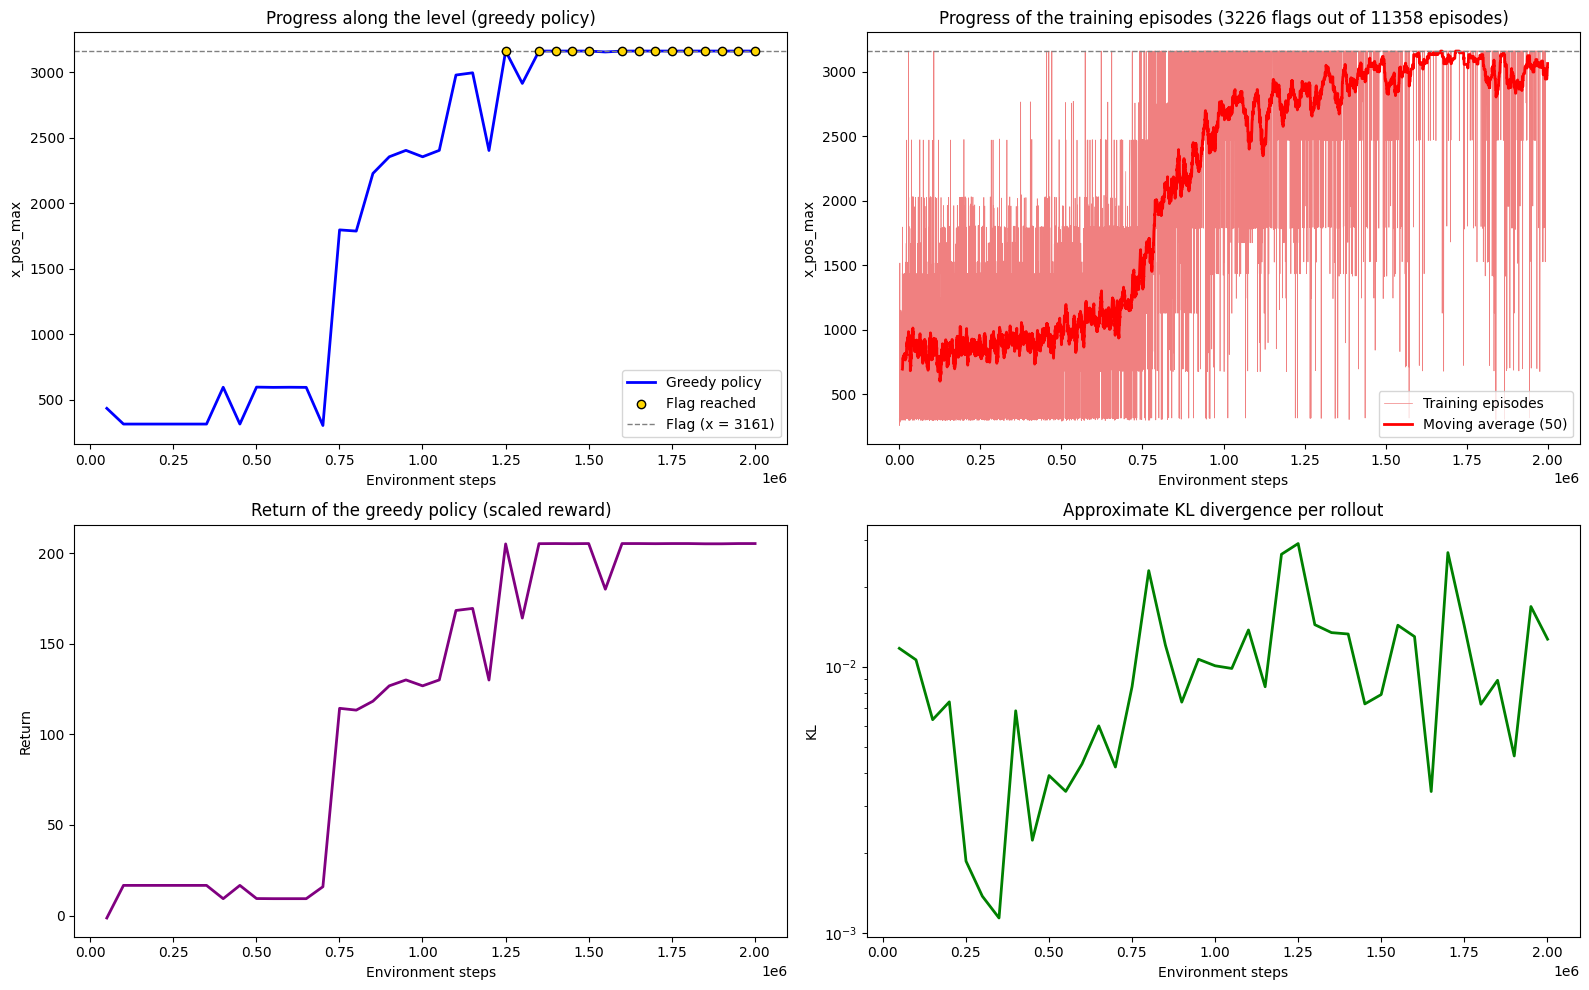

Best progress of the greedy policy: 3161 pixels, flags reached in 14 of 40 evaluations, training time 2.2 h


In [21]:
evaluations = mario_ppo["evaluations"]
steps = np.array([e["step"] for e in evaluations])
progress = np.array([e["progress"] for e in evaluations])
flags = np.array([e["flag"] for e in evaluations]) > 0

episodes = mario_ppo["episodes"]
episode_steps = np.cumsum([e["steps"] for e in episodes])            # environment steps (all environments)
episode_progress = np.array([e["progress"] for e in episodes])
episode_flags = np.array([e["flag"] for e in episodes]) > 0

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# progress of the greedy policy
axes[0, 0].plot(steps, progress, color="blue", linewidth=2, label="Greedy policy")
axes[0, 0].scatter(steps[flags], progress[flags], color="gold", edgecolor="black", zorder=3, label="Flag reached")
axes[0, 0].axhline(3161, color="gray", linestyle="--", linewidth=1, label="Flag (x = 3161)")
axes[0, 0].set_title("Progress along the level (greedy policy)")
axes[0, 0].set_xlabel("Environment steps")
axes[0, 0].set_ylabel("x_pos_max")
axes[0, 0].legend()

# progress of the training episodes
window = 50
axes[0, 1].plot(episode_steps, episode_progress, color="lightcoral", linewidth=0.5, label="Training episodes")
if len(episodes) >= window:
    kernel = np.ones(window) / window
    axes[0, 1].plot(episode_steps[window - 1:], np.convolve(episode_progress, kernel, mode="valid"),
                    color="red", linewidth=2, label=f"Moving average ({window})")
axes[0, 1].axhline(3161, color="gray", linestyle="--", linewidth=1)
axes[0, 1].set_title(f"Progress of the training episodes ({int(episode_flags.sum())} flags out of {len(episodes)} episodes)")
axes[0, 1].set_xlabel("Environment steps")
axes[0, 1].set_ylabel("x_pos_max")
axes[0, 1].legend()

# return of the greedy policy
axes[1, 0].plot(steps, [e["return"] for e in evaluations], color="purple", linewidth=2)
axes[1, 0].set_title("Return of the greedy policy (scaled reward)")
axes[1, 0].set_xlabel("Environment steps")
axes[1, 0].set_ylabel("Return")

# approximate KL divergence
axes[1, 1].plot(steps, [e["kl"] for e in evaluations], color="green", linewidth=2)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Approximate KL divergence per rollout")
axes[1, 1].set_xlabel("Environment steps")
axes[1, 1].set_ylabel("KL")

plt.tight_layout()
plt.show()

print(f"Best progress of the greedy policy: {mario_ppo['best_progress']:.0f} pixels, "
      f"flags reached in {int(flags.sum())} of {len(flags)} evaluations, "
      f"training time {mario_ppo['elapsed'] / 3600:.1f} h")

Watch the agent playing: load the best policy saved during training (not the final network) and show one episode with the greedy policy.

In [ ]:
best = torch.load("temp/mario_ppo_best.pt", map_location=device, weights_only=False)

# a fresh network with the shape of the wrapped environment (4 x 84 x 84 states, 7 actions)
mario = make_mario_env("1-1")
net = ActorCriticNetwork(mario).to(device)
net.load_state_dict(best["network"])
print("Best policy:", best["evaluation"])

show_policy(mario, greedy_pi, n_episodes=1, max_steps=1000)

### Part IV - Generalisation

18 - The emulator is deterministic and the agent has seen one level only: has it learned to play Super Mario Bros, or has it memorised a sequence of actions? To find out, we test the best policy on the training level, on a different level and on levels drawn at random from the whole game. The first versions of the package provided a SuperMarioBrosRandomStages-v0 environment for this purpose; version 9 does not, so write a RandomStages class, a gymnasium.Env that holds the environments of a list of levels (created when first needed: there are 32 of them) and at every reset() picks one at random, delegating step() and render() to it and adding the level to the info dictionary. It is a raw environment like the one returned by gymnasium.make(), so wrap_mario_env() applies the usual wrappers on top of it.

In [23]:
class RandomStages(gymnasium.Env):

    metadata = {"render_modes": ["rgb_array"]}

    def __init__(self, stages, render_mode="rgb_array"):
        super().__init__()
        self.stages = list(stages)
        self.render_mode = render_mode
        self.envs = {}          # the environments of the levels, created when first needed
        self.env = None         # the environment of the current episode
        self.stage = None

        # all the levels have the same screen and the same controller
        first = self.environment(self.stages[0])
        self.observation_space = first.observation_space
        self.action_space = first.action_space

    def environment(self, stage):
        if stage not in self.envs:
            self.envs[stage] = gymnasium.make(f"SuperMarioBros-{stage}-v0", render_mode=self.render_mode)
        return self.envs[stage]

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        # a random level for the new episode
        self.stage = self.stages[self.np_random.integers(len(self.stages))]
        self.env = self.environment(self.stage)
        state, info = self.env.reset(seed=seed)
        info["stage_id"] = self.stage
        return state, info

    def step(self, action):
        state, reward, terminated, truncated, info = self.env.step(action)
        info["stage_id"] = self.stage
        return state, reward, terminated, truncated, info

    def render(self):
        return self.env.render()

    def close(self):
        for env in self.envs.values():
            env.close()


ALL_STAGES = [f"{world}-{stage}" for world in range(1, 9) for stage in range(1, 5)]

Evaluate the best policy, greedy and stochastic (several episodes, since the policy is stochastic and the levels random), on "1-1", on "1-2" and on RandomStages over all the levels of the game, comparing the progress. Then look at the random levels one episode at a time.

In [24]:
# the best policy of task 17 is loaded in net
tests = {
    "1-1 (training level)": make_mario_env("1-1"),
    "1-2 (underground)": make_mario_env("1-2"),
    "random level": wrap_mario_env(RandomStages(ALL_STAGES)),
}

print(f"{'environment':>22} | {'greedy (3 ep.)':>22} | {'stochastic (8 ep.)':>22}")
print(f"{'':>22} | {'progress':>14} {'flags':>7} | {'progress':>14} {'flags':>7}")
for name, env in tests.items():
    env.reset(seed=0)
    greedy_results = evaluate(env, greedy_pi, episodes=3)
    stochastic_results = evaluate(env, stochastic_pi, episodes=8)
    print(f"{name:>22} | {greedy_results['progress']:14.0f} {greedy_results['flag']:7.2f} | "
          f"{stochastic_results['progress']:14.0f} {stochastic_results['flag']:7.2f}")
    env.close()

           environment |         greedy (3 ep.) |     stochastic (8 ep.)
                       |       progress   flags |       progress   flags
  1-1 (training level) |           3161    1.00 |           2205    0.25
     1-2 (underground) |            183    0.00 |            436    0.00
          random level |            424    0.00 |            835    0.12


In [25]:
# a closer look at the random levels: one episode at a time, with the level drawn
env = wrap_mario_env(RandomStages(ALL_STAGES))
env.reset(seed=1)

for episode in range(8):
    state, info = env.reset()
    stage, done, steps = info["stage_id"], False, 0
    while not done and steps < 10_000:
        state, _, terminated, truncated, info = env.step(stochastic_pi(state))
        done = terminated or truncated
        steps += 1
    print(f"level {stage}: progress {info['x_pos_max']:5d}, flag {int(info['flag_get'])}, {steps:5d} steps")

env.close()

level 5-1: progress   272, flag 0,    27 steps
level 7-1: progress   993, flag 0,   198 steps
level 8-3: progress   443, flag 0,    82 steps
level 1-2: progress   664, flag 0,    88 steps
level 2-1: progress   458, flag 0,    48 steps
level 7-3: progress  1080, flag 0,   111 steps
level 8-3: progress  1137, flag 0,   175 steps
level 2-4: progress   344, flag 0,    34 steps


The collapse is expected, and it is the main lesson of this lab. In our run the greedy policy completes the training level at every attempt (the environment is deterministic, so it replays the same winning trajectory), and the stochastic one gets to 2200 pixels on average and completes the level one time out of four. On 1-2 the same network gets to 183 pixels, less than a third of what the random policy does, and on the random levels it rarely gets past the first obstacles (with a few exceptions among the levels that look like 1-1: same background, same colours, same kinds of obstacles). Two different things have gone wrong, and it is worth separating them.

The first is **overfitting of the perception**. The emulator is deterministic and the training set is a single level, so the states seen during training all lie along a thin tube around one trajectory: the convolutional features have learned to tell apart the frames of that tube, not to recognise a pipe or a Goomba in general. The underground level has a different background, different colours and a different layout: its frames are outside the training distribution, the features computed on them are meaningless, and the policy behaves like an untrained one. Often worse, because it is confident: a trained network has sharp preferences, and when they are wrong it repeats the wrong action instead of trying others. This is why the greedy policy collapses more than the stochastic one outside the training level (183 against 436 pixels on 1-2), while on the training level the order is reversed.

The second is **overfitting of the control**. Even where the perception transfers, the policy has learned *when* to jump along a memorised sequence of situations, not *why*. Nothing in the objective asks for more: PPO maximises the return on the distribution of states that its own policy visits, and with a deterministic environment and a single level this distribution is tiny. Supervised learning has the same problem, and the same cures: more data (more levels, task 19), data augmentation (random crops, colour changes, sticky actions, random initial no-ops to inject variability, as in the Pong lab) and benchmarks that measure generalisation explicitly, such as Procgen, whose levels are procedurally generated so that the test levels are never seen in training. A learning curve on a single deterministic level, however impressive, says nothing about generalisation: it measures optimisation, not intelligence.

19 - Some experiments to try, each a modification of a few lines above (the generalisation problem of task 18 has its own task, 20):

- **Action set**: train with RIGHT_ONLY (5 actions) instead of SIMPLE_MOVEMENT. The level can be completed without ever moving left, and a smaller action space makes exploration easier: does the agent learn faster? And with COMPLEX_MOVEMENT?
- **Discount factor**: train with $\gamma = 0.99$ and compare the learning curves (and the KL divergence).
- **Reward shaping**: the reward is a design choice. Write a wrapper that removes the time penalty (does the agent still run, or does it learn to wait in a safe place?), or one that keeps only the progress term, or one that adds a large bonus to the flag. Which components are really necessary?
- **Speed**: the emulator takes most of the training time, and the 8 environments run one after the other. Gymnasium's AsyncVectorEnv runs each environment in its own process: rewrite create_environments() and collect_rollout() around it (pay attention to the automatic reset of the vectorised environments) and measure the speed-up on your machine.
- **Curiosity**: Super Mario Bros is the environment of the Intrinsic Curiosity Module paper (Pathak et al., 2017), in which the agent is rewarded for reaching states that its forward model cannot predict, with no extrinsic reward at all. Implement the intrinsic reward (a forward model on the features of a small encoder, the prediction error as reward) and train with it alone: how far does the curious agent get?

20 - What can be done against the collapse of task 18? The two causes suggest two families of remedies, and this task sets up the experiments to compare them. Both cost as much as the main training, so they are meant as a project: one experiment per group, with the table of this task as the common ground.

**(a) More variety: several levels.** The cure for overfitting in supervised learning is more data; here, more levels. We train on three levels of the first world (1-1, 1-3 and 1-4, drawn at random at every reset with RandomStages) and we keep the others as **held-out test levels**: 1-2 and the four levels of the second world. Without held-out levels, a learning curve measures optimisation, not generalisation. The learning on the training levels will be slower (the budget is shared among them, and the policy must work on all of them): this is the price of generalisation.

**(b) Variety plus invariance: sticky actions and random shifts.** Two cheap additions that attack the two causes directly. *Sticky actions* (with probability $p = 0.25$ the previous action is repeated, as in the Atari benchmark) break the determinism of the emulator: a sequence of actions memorised open-loop no longer works, so the policy must react to what it sees. *Random shifts* (the image is padded by 4 pixels and a random 84x84 crop is taken, the simplest data augmentation of deep RL) teach the convolutional trunk that the absolute position of the pixels does not matter, which a single trajectory never teaches. The augmentation is applied only during the optimization, through the augment hook of optimize(): the rollout is collected on the real frames.

**(c) Transfer instead of zero-shot (not implemented, a trace).** If the goal is to play 1-2, the fair test is not zero-shot but fine-tuning: add an init_from parameter to ppo() that loads the weights of the 1-1 policy into the network before the loop, train on 1-2 and compare the learning curve with a training from scratch. If the features transfer even in part, the curve is much steeper: a way to show that the agent did not learn "nothing", but something partial.

Write the StickyActions wrapper (applied to the raw environment, before JoypadSpace, so that it acts on every frame), the random_shift() augmentation, and extend make_mario_env() so that it accepts a list of levels and the sticky-action probability. Then run the two trainings, with the same budget of the main one, and build the comparison table: the three policies (1-1 only, (a), (b)) evaluated on the training levels, on 1-2 and on the second world.

In [26]:
class StickyActions(gymnasium.Wrapper):

    def __init__(self, env, p=0.25):
        super().__init__(env)
        self.p = p
        self.previous_action = 0    # no-op

    def reset(self, **kwargs):
        self.previous_action = 0
        return self.env.reset(**kwargs)

    def step(self, action):
        # with probability p, the previous action is repeated instead of the chosen one
        if random.random() < self.p:
            action = self.previous_action
        self.previous_action = action
        return self.env.step(action)


def random_shift(states, pad=4):

    # pad each frame by replicating its border, then crop a random window of the original size
    n, channels, height, width = states.shape
    padded = torch.nn.functional.pad(states, (pad, pad, pad, pad), mode="replicate")

    shifted = torch.empty_like(states)
    for i in range(n):
        dx, dy = random.randint(0, 2 * pad), random.randint(0, 2 * pad)
        shifted[i] = padded[i, :, dy:dy + height, dx:dx + width]

    return shifted


def make_mario_env(stage="1-1", actions=SIMPLE_MOVEMENT, reward_scale=15.0, render_mode="rgb_array", sticky=0.0):

    # a single level, or a list of levels drawn at random at every reset
    if isinstance(stage, str):
        env = gymnasium.make(f"SuperMarioBros-{stage}-v0", render_mode=render_mode)
    else:
        env = RandomStages(stage, render_mode=render_mode)

    # sticky actions on the raw frames
    if sticky > 0:
        env = StickyActions(env, p=sticky)

    return wrap_mario_env(env, actions, reward_scale)

In [ ]:
# a look at the augmentation: the same state, shifted three times
mario = make_mario_env("1-1")
state, _ = mario.reset()
for _ in range(30):
    state, _, _, _, _ = mario.step(1)

shifted = random_shift(to_tensor(np.asarray(state)[None].repeat(3, axis=0)))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
axes[0].imshow(state[-1], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("original")
for k in range(3):
    axes[k + 1].imshow(shifted[k, -1].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[k + 1].set_title(f"random shift {k + 1}")
for ax in axes:
    ax.axis("off")
plt.show()

In [28]:
TRAINING_LEVELS = ["1-1", "1-3", "1-4"]
TEST_LEVELS = ["1-2", "2-1", "2-2", "2-3", "2-4"]

# (a) three levels of the first world
mario_ppo_levels = train(
    name="mario_ppo_levels",
    max_steps=2_000_000,
    eval_every=50_000,
    env_kwargs=dict(stage=TRAINING_LEVELS),
    gamma=0.9,
    learning_rate=0.00025,
    seed=42,
)

Step    50176 | greedy: x   229, return   11.3, flag 0 | last 20 training episodes: x   457, return   26.0, flags 0 | KL 0.0123 | 3 min
Step   100352 | greedy: x   460, return   26.3, flag 0 | last 20 training episodes: x   544, return   31.8, flags 0 | KL 0.0058 | 6 min
Step   150528 | greedy: x   460, return   26.3, flag 0 | last 20 training episodes: x   472, return   27.1, flags 0 | KL 0.0046 | 9 min
Step   200704 | greedy: x  1204, return   75.1, flag 0 | last 20 training episodes: x   505, return   29.2, flags 0 | KL 0.0039 | 13 min
Step   250880 | greedy: x   419, return   23.6, flag 0 | last 20 training episodes: x   711, return   42.7, flags 0 | KL 0.0076 | 16 min
Step   300032 | greedy: x   435, return   -1.3, flag 0 | last 20 training episodes: x   923, return   56.6, flags 0 | KL 0.0030 | 19 min
Step   350208 | greedy: x  2244, return  143.0, flag 0 | last 20 training episodes: x  1091, return   67.8, flags 2 | KL 0.0091 | 22 min
Step   400384 | greedy: x  2073, return  132

In [29]:
# (b) the same levels, with sticky actions and random shifts
mario_ppo_levels_aug = train(
    name="mario_ppo_levels_aug",
    max_steps=2_000_000,
    eval_every=50_000,
    env_kwargs=dict(stage=TRAINING_LEVELS, sticky=0.25),
    augment=random_shift,
    gamma=0.9,
    learning_rate=0.00025,
    seed=42,
)

Step    50176 | greedy: x   229, return   11.3, flag 0 | last 20 training episodes: x   617, return   36.4, flags 0 | KL 0.0038 | 3 min
Step   100352 | greedy: x   234, return   11.5, flag 0 | last 20 training episodes: x   697, return   41.8, flags 0 | KL 0.0009 | 6 min
Step   150528 | greedy: x   553, return   32.5, flag 0 | last 20 training episodes: x   528, return   30.8, flags 0 | KL 0.0040 | 10 min
Step   200704 | greedy: x   553, return   32.5, flag 0 | last 20 training episodes: x   858, return   52.4, flags 0 | KL 0.0060 | 13 min
Step   250880 | greedy: x   435, return   24.7, flag 0 | last 20 training episodes: x   595, return   35.0, flags 0 | KL 0.0139 | 16 min
Step   300032 | greedy: x   434, return   -1.4, flag 0 | last 20 training episodes: x   616, return   36.4, flags 0 | KL 0.0096 | 19 min
Step   350208 | greedy: x   553, return   32.5, flag 0 | last 20 training episodes: x   702, return   41.8, flags 0 | KL 0.0242 | 22 min
Step   400384 | greedy: x   553, return   3

Compare the three policies. Each is evaluated with its stochastic version (the greedy one collapses first, as seen in task 18) on every level, with a few episodes per level; on the levels of the second world the progress is what matters, since none of the policies is expected to reach the flag there. The best policy of a training on several levels was chosen on a random level, so "best" is a noisy choice: the comparison would be fairer with the final checkpoints (temp/<name>_checkpoint.pt), which you can try as well.

In [35]:
def load_policy(name):
    best = torch.load(f"temp/{name}_best.pt", map_location=device, weights_only=False)
    net.load_state_dict(best["network"])


def progress_on(levels, episodes=3):
    results = {}
    for level in levels:
        env = make_mario_env(level)
        env.reset(seed=0)
        results[level] = evaluate(env, stochastic_pi, episodes=episodes)["progress"]
        env.close()
    return results


policies = {"1-1 only": "mario_ppo", "(a) three levels": "mario_ppo_levels", "(b) three levels + sticky + shift": "mario_ppo_levels_aug"}
levels = TRAINING_LEVELS + TEST_LEVELS

net = ActorCriticNetwork(make_mario_env("1-1")).to(device)
table = {}
for label, name in policies.items():
    load_policy(name)
    table[label] = progress_on(levels)

print(f"{'policy':>34} | " + " ".join(f"{level:>6}" for level in levels) + " | train   test")
for label, row in table.items():
    train_mean = np.mean([row[level] for level in TRAINING_LEVELS])
    test_mean = np.mean([row[level] for level in TEST_LEVELS])
    print(f"{label:>34} | " + " ".join(f"{row[level]:6.0f}" for level in levels) + f" | {train_mean:5.0f} {test_mean:6.0f}")

                            policy |    1-1    1-3    1-4    1-2    2-1    2-2    2-3    2-4 | train   test
                          1-1 only |   3161    346    231    189    450   1096   1080    300 |  1246    623
                  (a) three levels |   3161    579   2253    515    542   1618    609    347 |  1998    726
 (b) three levels + sticky + shift |   2516    427   1694    406    398   1483   1166    347 |  1546    760


What to expect, and how to read the table. The policy trained on 1-1 only should be the best on 1-1 and the worst everywhere else: it is the most optimised and the least general. Policy (a) should get less far on 1-1 (the budget is shared) but much farther on 1-3 and 1-4, and somewhat farther on the test levels that resemble the training ones; policy (b) should be at least as good as (a) on the test levels, and the gap between its training and test averages should be smaller: the invariances it has learned are exactly those that the test levels require. Do not expect miracles on 1-2 and on the castle 2-4: they look like nothing in the training set, and no regularisation can replace the missing data. Three levels are very few; the benchmarks of generalisation in reinforcement learning use hundreds or thousands of procedurally generated levels for a reason, and the gap closes only slowly with their number. If you want to go further, the next steps in the literature are a larger network with residual blocks (the IMPALA CNN), which generalises better than the Nature CNN of this lab, and self-supervised auxiliary losses on the trunk, which force the features to encode the dynamics of the game rather than the position along a level.